In [38]:
#CNN

In [51]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_olivetti_faces
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Flatten, Dense,Dropout,Conv2D,MaxPooling2D
from sklearn.model_selection import train_test_split
import numpy as np

In [40]:
data = fetch_olivetti_faces()

In [41]:
X=data.data

In [42]:
y=data.target

In [43]:
print("Shape of X", X.shape)

Shape of X (400, 4096)


In [44]:
print("Shape of y", y.shape)

Shape of y (400,)


In [45]:
#reshape

X= X.reshape(-1,64,64,1)


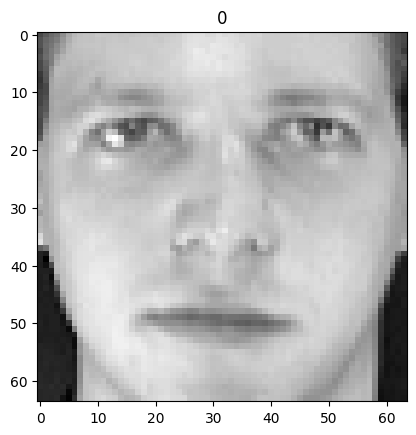

In [46]:
#Display Sample Images

plt.imshow(X[0], cmap='gray')
plt.title(y[0])
plt.show()

In [47]:
#check image dimension and no of classes
print("Image Dimensions:", X.shape)

Image Dimensions: (400, 64, 64, 1)


In [48]:
print("Number of classes:", len(np.unique(y)))

Number of classes: 40


In [50]:
#Normalization

print("minimum values :", X.min())
print("maximum values :", X.max())

minimum values : 0.0
maximum values : 1.0


Since the data is already normalized, there is no need for normalization again.

In [80]:
#split the data into training and testing sets.

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

In [81]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(320, 64, 64, 1)
(80, 64, 64, 1)
(320,)
(80,)


In [82]:
#Build CNN
model = Sequential()

In [83]:
#add first  ConV2D layer
model.add(layers.Conv2D(32,(3,3),activation='relu',input_shape=(64,64,1)))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [84]:
#add maxpooling layer
model.add(layers.MaxPooling2D((2,2)))

In [85]:
#Second ConV2D layer
model.add(layers.Conv2D(64,(3,3),activation='relu'))

In [86]:
#MaxPooling layer
model.add(layers.MaxPooling2D((2,2)))

In [87]:
#Third Conv2D Layer
model.add(layers.Conv2D(128,(3,3),activation='relu'))

In [88]:
#MaxPooling layer
model.add(layers.MaxPooling2D((2,2)))

In [89]:
#Flatten Layer
model.add(layers.Flatten())

In [90]:
#Fully Connected layer
model.add(layers.Dense(128,activation='relu'))

In [91]:
#Output layer
model.add(layers.Dense(40,activation='softmax'))

In [106]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [107]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 62, 62, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 31, 31, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 29, 29, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 12, 12, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 4608)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │       589,952 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 40)             │         5,160 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 687,784 (2.62 MB)

 Trainable params: 687,784 (2.62 MB)

 Non-trainable params: 0 (0.00 B)

In [108]:
history = model.fit(X_train,y_train, epochs=10,validation_data = (X_test,y_test))

Epoch 1/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 6s 367ms/step - accuracy: 0.0188 - loss: 3.7024 - val_accuracy: 0.0250 - val_loss: 3.6870
Epoch 2/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 241ms/step - accuracy: 0.0250 - loss: 3.6875 - val_accuracy: 0.0250 - val_loss: 3.6808
Epoch 3/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 239ms/step - accuracy: 0.0281 - loss: 3.6758 - val_accuracy: 0.0250 - val_loss: 3.6623
Epoch 4/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 3s 240ms/step - accuracy: 0.0250 - loss: 3.6434 - val_accuracy: 0.0250 - val_loss: 3.6129
Epoch 5/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 3s 323ms/step - accuracy: 0.0437 - loss: 3.5609 - val_accuracy: 0.1500 - val_loss: 3.5033
Epoch 6/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 3s 319ms/step - accuracy: 0.1406 - loss: 3.3214 - val_accuracy: 0.1500 - val_loss: 3.1473
Epoch 7/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 244ms/step - accuracy: 0.2500 - loss: 2.9047 - val_accuracy: 0.4125 - val_loss: 2.5628
Epoch 8/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 3s 309ms/step - accuracy: 0.4219 - loss: 2.2160 - val_accuracy: 0.

In [110]:
loss,accuracy=model.evaluate(X_test,y_test)

3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 236ms/step - accuracy: 0.6750 - loss: 1.0861


In [111]:
print("Test Accuracy:", accuracy)

Test Accuracy: 0.675000011920929


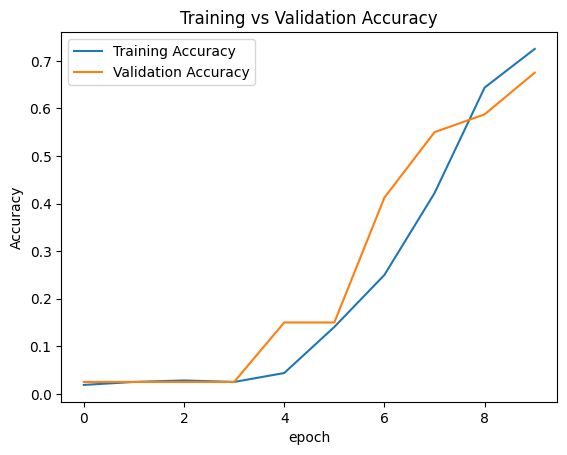

In [114]:
plt.plot(history.history["accuracy"],label="Training Accuracy")
plt.plot(history.history["val_accuracy"],label="Validation Accuracy")
plt.xlabel("epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()
plt.show()

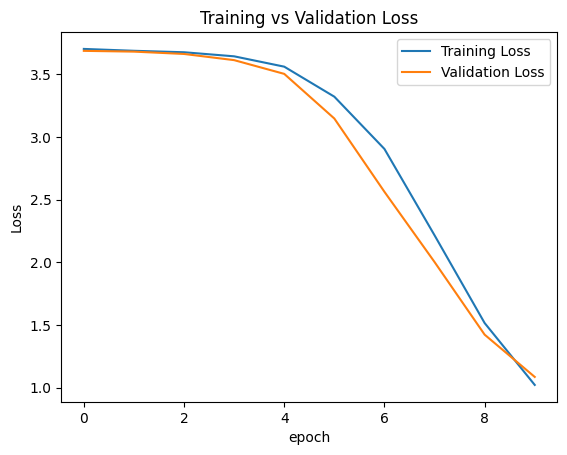

In [115]:
plt.plot(history.history["loss"],label="Training Loss")
plt.plot(history.history["val_loss"],label="Validation Loss")
plt.xlabel("epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.show()

In [116]:
#make predictions
predictions = model.predict(X_test)

3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 146ms/step


In [117]:
predicted_class=np.argmax(predictions,axis=1)

In [119]:
print("actuals", y_test[:10])
print("Predictions", predicted_class[:10])

actuals [ 1 35 18 16 39 23 32 19  3 34]
Predictions [30 35 35 16 20  0 32 19  3 34]


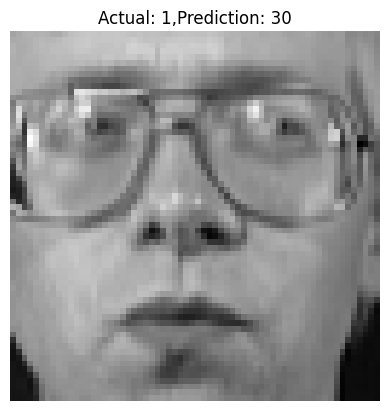

In [120]:
#display predicted face
plt.imshow(X_test[0].reshape(64,64),cmap="gray")
plt.title(f"Actual: {y_test[0]},Prediction: {predicted_class[0]}")
plt.axis('off')
plt.show()